# AML · 02 Preprocessing — clean, split and transform
Run after `01_eda.ipynb`. No model selection uses calibration or test rows.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Schema and explicit configuration

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
import joblib
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "AML"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

CONFIG = {
    "seed": 42,
    "train_end": "2018-12-31", "validation_end": "2019-12-31", "calibration_end": "2020-12-31",
    "max_train_rows": 300000, "max_tuning_rows": 50000, "threads": 4,
    "xgb_estimators": 1000, "xgb_depths": [4, 6],
    "alpha": 0.1, "explanation_rows": 2000,
}
CONFIG["data"] = str(CSV)

## 2. Cleaning and chronological partitions
Remove exact duplicates before splitting. Do not impute targets, dates or missing site identifiers. Keep original source-row IDs for traceability.

| Partition | Dates | Purpose |
|---|---|---|
| Training | Through 2018 | Fit preprocessing and model parameters |
| Validation | 2019 | Early stopping and model selection |
| Calibration | 2020 | Held-out residual interval radius |
| Test | 2021–2023 | Final comparison after selection |

Seed 42 samples 300,000 historical training rows and 50,000 validation tuning rows. All 202,886 test rows are evaluated. Historical sites can recur, so this is not an unseen-site evaluation.

In [2]:
def read_dataset(path):
    df = pd.read_csv(path)
    required = set(META + FEATURES + [TARGET, "CCME_WQI"])
    if required - set(df.columns):
        raise ValueError(f"Dataset lacks columns: {sorted(required - set(df.columns))}")
    return df

def prepare(frame):
    """Keep source row IDs for traceability; never impute a target or a date."""
    df = frame.copy()
    df.insert(0, "source_row", np.arange(len(df)))
    duplicates = df.drop(columns="source_row").duplicated()
    date = pd.to_datetime(df.Date, format="%d-%m-%Y", errors="coerce")
    y = pd.to_numeric(df[TARGET], errors="coerce")
    invalid = date.isna() | ~y.between(0, 100) | df.Country.isna() | df.Area.isna()
    counts = {
        "exact_duplicates_removed": int(duplicates.sum()),
        "invalid_metadata_or_target": int(invalid.sum()),
    }
    df = df.loc[~duplicates & ~invalid].copy()
    df["parsed_date"] = date.loc[df.index]
    df[TARGET] = y.loc[df.index]
    return df, counts

def temporal_split(df, config):
    bounds = [pd.Timestamp(config[k]) for k in ["train_end", "validation_end", "calibration_end"]]
    if not bounds[0] < bounds[1] < bounds[2]:
        raise ValueError("Split boundaries must increase strictly")
    date = df.parsed_date
    masks = [
        date <= bounds[0],
        (date > bounds[0]) & (date <= bounds[1]),
        (date > bounds[1]) & (date <= bounds[2]),
        date > bounds[2],
    ]
    splits = dict(zip(["train", "validation", "calibration", "test"], [df.loc[m].copy() for m in masks]))
    if any(part.empty for part in splits.values()):
        raise ValueError("Every chronological partition must contain observations")
    return splits

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

def split_summary(part):
    return {
        "rows": len(part),
        "start": str(part.parsed_date.min().date()),
        "end": str(part.parsed_date.max().date()),
        "countries": part.Country.value_counts().to_dict(),
        "sites": int(part.groupby(["Country", "Area"]).ngroups),
        "mean_target": float(part[TARGET].mean()),
    }

## 3. Fit transforms on training only
The eight measurements become 16 inputs after adding missing/invalid flags. Median imputation uses only the training sample. **XGBoost uses unscaled inputs** — trees split on thresholds, so scaling is unnecessary. The Ridge baseline additionally uses `asinh` and standard scaling, because a linear model is sensitive to skewed concentrations.

`AML/_working/` is a disposable local cache connecting the notebooks; it is excluded from Git.

In [3]:
print("Reading and cleaning the complete combined dataset...", flush=True)
raw = read_dataset(ensure_csv())
audit_path = WORK / "data_audit.json"
audit = json.loads(audit_path.read_text()) if audit_path.exists() else {}
clean, removed = prepare(raw)
audit.update(removed)
splits = temporal_split(clean, CONFIG)
manifest = {key: split_summary(part) for key, part in splits.items()}
train = sample(splits["train"], CONFIG["max_train_rows"], CONFIG["seed"])
tuning = sample(splits["validation"], CONFIG["max_tuning_rows"], CONFIG["seed"])
manifest["training_rows_used"] = len(train)
manifest["tuning_rows_used"] = len(tuning)
train_sites = pd.MultiIndex.from_frame(splits["train"][["Country", "Area"]])
test_sites = pd.MultiIndex.from_frame(splits["test"][["Country", "Area"]])
manifest["test_rows_at_sites_seen_before_2019"] = float(test_sites.isin(train_sites).mean())
x, y = quality_features(train), train[TARGET].to_numpy()
xv, yv = quality_features(tuning), tuning[TARGET].to_numpy()

# Trees: median imputation only.
tree_pre = SimpleImputer(strategy="median", keep_empty_features=True)
xt, xvt = tree_pre.fit_transform(x), tree_pre.transform(xv)
# Linear baseline: asinh reduces concentration skew, then standardize.
linear_pre = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    FunctionTransformer(np.arcsinh, validate=False),
    StandardScaler(),
)
xl, xvl = linear_pre.fit_transform(x), linear_pre.transform(xv)

manifest["retained_rows"] = len(clean)
audit["retained_rows"] = len(clean)
bundle = {
    "train": train, "tuning": tuning,
    "splits": {name: splits[name] for name in ["validation", "calibration", "test"]},
    "manifest": manifest, "audit": audit, "config": CONFIG,
    "tree_pre": tree_pre, "linear_pre": linear_pre,
    "xt": xt, "xvt": xvt, "xl": xl, "xvl": xvl, "y": y, "yv": yv,
}
joblib.dump(bundle, WORK / "prepared.joblib", compress=3)
dump_json(WORK / "split_manifest.json", manifest)
display(pd.DataFrame({k: v for k, v in manifest.items() if isinstance(v, dict)}).T)
print(f"Training sample: {len(train):,}; tuning sample: {len(tuning):,}")
print(f"Test rows at historical sites: {manifest['test_rows_at_sites_seen_before_2019']:.1%}")

Reading and cleaning the complete combined dataset...


,rows,start,end,countries,sites,mean_target
train,2478761,1940-01-02,2018-12-28,"{'England': 1887124, 'USA': 371009, 'Ireland':...",55731,84.148022
validation,87177,2019-01-01,2019-12-31,"{'England': 64121, 'Ireland': 14404, 'USA': 82...",14705,90.376429
calibration,49182,2020-01-01,2020-12-31,"{'England': 29453, 'Ireland': 12846, 'USA': 65...",11484,91.920604
test,202886,2021-01-01,2023-12-17,"{'England': 147199, 'Ireland': 36230, 'USA': 1...",17462,91.410002


Training sample: 300,000; tuning sample: 50,000
Test rows at historical sites: 85.9%


## 4. Inspect separation and fitted values

In [4]:
assert splits["validation"].parsed_date.min() > pd.Timestamp(CONFIG["train_end"])
assert splits["test"].parsed_date.min() > pd.Timestamp(CONFIG["calibration_end"])
assert xt.shape[1] == xl.shape[1] == 16
assert np.isfinite(xt).all() and np.isfinite(xl).all()
display(pd.DataFrame({"input": x.columns, "training_median": tree_pre.statistics_}))

,input,training_median
0,Ammonia (mg/l),0.060
1,Biochemical Oxygen Demand (mg/l),2.600
2,Dissolved Oxygen (mg/l),10.200
3,Orthophosphate (mg/l),0.122
4,pH (ph units),7.780
5,Temperature (cel),11.460
6,Nitrogen (mg/l),4.140
7,Nitrate (mg/l),4.500
8,Ammonia (mg/l)__missing,0.000
9,Biochemical Oxygen Demand (mg/l)__missing,0.000


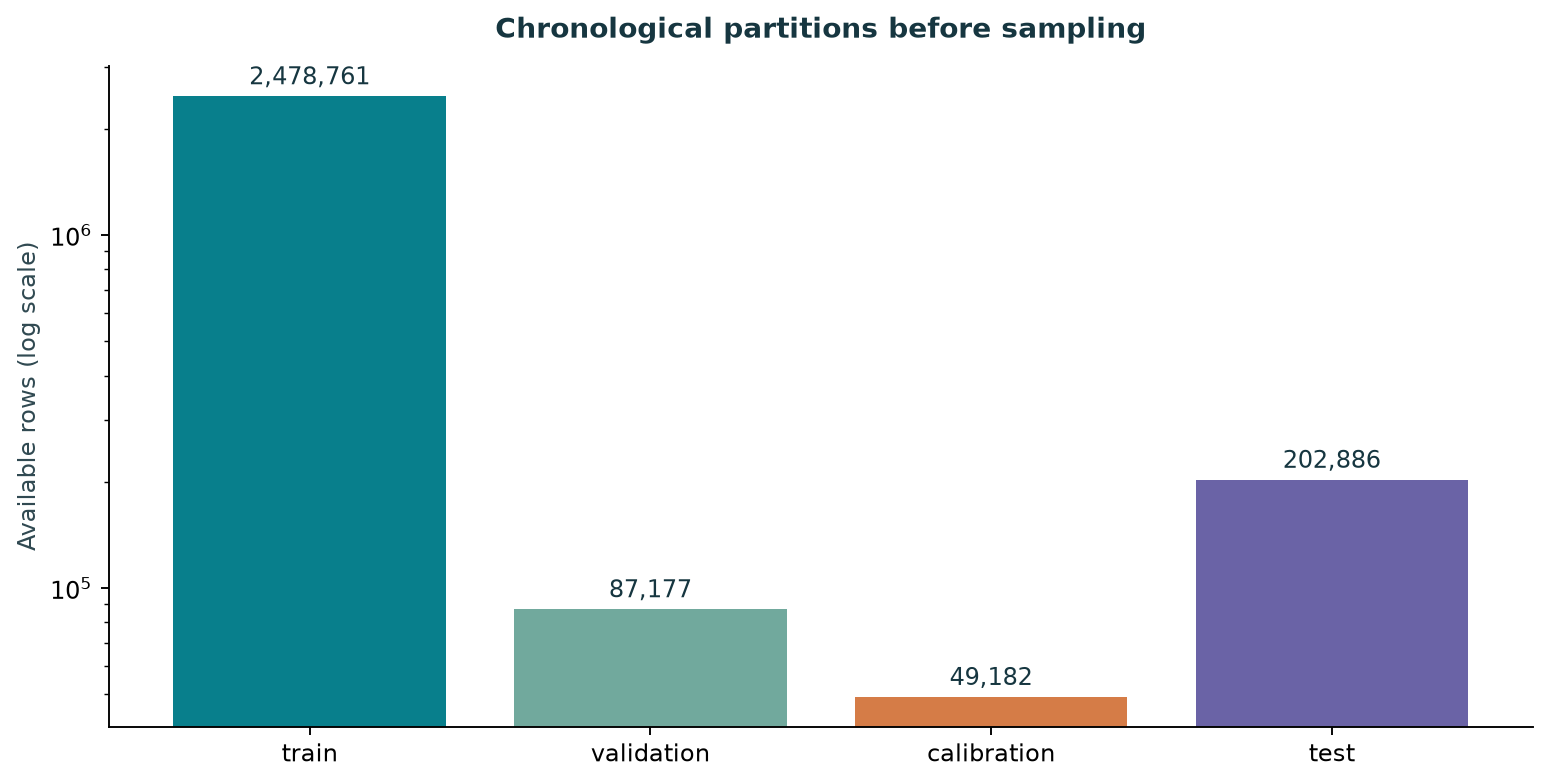

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
parts = ["train", "validation", "calibration", "test"]
counts = [manifest[k]["rows"] for k in parts]
ax.bar(parts, counts, color=["#087f8c", "#71a99d", "#d57c47", "#6a63a6"])
ax.set(yscale="log", ylabel="Available rows (log scale)", title="Chronological partitions before sampling")
for i, count in enumerate(counts):
    ax.text(i, count * 1.08, f"{count:,}", ha="center")
show_figure(fig, "temporal_split.png")

## Next step
Run **03_xgboost_model.ipynb** to train, compare, explain, save and reload the models.